<a href="https://colab.research.google.com/github/seo104/26-2-ESAA/blob/main/%EC%97%91%EC%8A%A4%ED%8A%B8%EB%9D%BC_%ED%8A%B8%EB%A6%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##와인 품질 분류 모델링 - Extra Trees

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_val_score
)
from sklearn.base import clone

# 데이터 불러오기
train = pd.read_csv('/content/train(와인).csv')
test = pd.read_csv('/content/test(와인).csv')

print('Train 데이터 크기:', train.shape)
print('Test 데이터 크기:', test.shape)

Train 데이터 크기: (5497, 14)
Test 데이터 크기: (1000, 13)


###1. 공통 전처리
회의에서 확정한 전처리 기준은
- 레드와 화이트 데이터를 통합하여 사용
- type은 화이트=1, 레드=0인 is_white로 변환
- bound_so2(total sulfur dioxide - free sulfur dioxide)를 추가
- density를 포함한 기존 화학 성분 변수는 모두 유지
- 이상치 삭제, 로그 변환, 중복 제거 및 불균형 처리는 적용하지 않음
- index와 quality는 입력 변수에서 제외

In [2]:
#공통 전처리 함수
def make_x(df):
    X = df.drop(columns=['index', 'quality'], errors='ignore').copy()

    X['is_white'] = X['type'].map({'red': 0, 'white': 1})
    X = X.drop(columns=['type'])

    X['bound_so2'] = (
        X['total sulfur dioxide'] - X['free sulfur dioxide']
    )
    return X


def make_xy(df):
    X = make_x(df)
    y = df['quality'].copy()
    return X, y


X, y = make_xy(train)
X_test = make_x(test)

print('X shape:', X.shape)
print('X_test shape:', X_test.shape)

X shape: (5497, 13)
X_test shape: (1000, 13)


###2. 기본 모델 및 검증 규칙
모든 모델은 동일한 검증 조건으로 비교
- 검증 방법: StratifiedKFold
- Fold 수: 5
- shuffle=True, random_state=42
- 평가 지표: Accuracy
- 결과 기록: Fold별 점수, 평균, 표준편차
- 기준선 Accuracy: 0.4395

먼저 회의에서 사용한 기본 Extra Trees 모델의 성능을 확인한다.

In [3]:
# 확정된 일반 교차검증
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate(model, X, y):
    scores = cross_val_score(
        clone(model),
        X,
        y,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    print('Fold별 Accuracy:', np.round(scores, 4))
    print(f'평균 Accuracy: {scores.mean():.4f}')
    print(f'표준편차: {scores.std():.4f}')

    return scores


# 기본 Extra Trees 모델
base_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

base_scores = evaluate(base_model, X, y)

Fold별 Accuracy: [0.6964 0.6836 0.6779 0.6797 0.6615]
평균 Accuracy: 0.6798
표준편차: 0.0112


###3. 하이퍼파라미터 튜닝
Extra Trees의 주요 하이퍼파라미터를 변경하여 성능을 비교한다.
- n_estimators: 트리 개수
- max_depth: 트리의 최대 깊이
- min_samples_split: 노드를 분할하기 위한 최소 샘플 수
- min_samples_leaf: 리프 노드에 필요한 최소 샘플 수
- max_features: 분할 시 고려할 변수 수

트리 깊이와 리프 샘플 수를 조절하여 과적합을 줄일 수 있는지 확인한다.

In [5]:
from sklearn.model_selection import RandomizedSearchCV

# 실험할 파라미터 범위
param_dist = {
    'n_estimators': [300, 500],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4],
    'max_features': [0.7, 0.9, 1.0]
}

# 기본 모델
et = ExtraTreesClassifier(
    random_state=42,
    n_jobs=1
)

# 무작위 하이퍼파라미터 탐색
search = RandomizedSearchCV(
    estimator=et,
    param_distributions=param_dist,
    n_iter=10,
    scoring='accuracy',
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=2
)

search.fit(X, y)

# 실험 결과 정리
results = []

for i, params in enumerate(search.cv_results_['params']):
    row = {
        '실험': i + 1,
        **params,
        'CV 평균': search.cv_results_['mean_test_score'][i],
        'CV 표준편차': search.cv_results_['std_test_score'][i]
    }

    for fold in range(5):
        row[f'Fold {fold+1}'] = (
            search.cv_results_[f'split{fold}_test_score'][i]
        )

    results.append(row)

result_df = pd.DataFrame(results).sort_values(
    'CV 평균', ascending=False
).reset_index(drop=True)

display(result_df.round(4))

print("최고 CV Accuracy:", search.best_score_)
print("최적 파라미터:", search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,실험,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,CV 평균,CV 표준편차,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,8,500,2,1,0.7,20.0,0.6780,0.0112,0.6918,0.6809,0.6679,0.6870,0.6624
1,1,500,5,2,1.0,30.0,0.6744,0.0105,0.6900,0.6745,0.6752,0.6752,0.6570
2,4,500,5,2,0.9,30.0,0.6742,0.0088,0.6855,0.6773,0.6697,0.6788,0.6597
3,7,300,5,3,0.9,30.0,0.6727,0.0143,0.6900,0.6855,0.6679,0.6706,0.6497
4,5,500,5,3,0.7,NaN,0.6669,0.0109,0.6836,0.6682,0.6724,0.6570,0.6533
5,6,500,5,3,0.9,20.0,0.6656,0.0099,0.6827,0.6645,0.6579,0.6688,0.6542
6,9,500,2,3,1.0,30.0,0.6653,0.0092,0.6773,0.6736,0.6588,0.6642,0.6524
7,3,300,2,4,1.0,20.0,0.6549,0.0096,0.6718,0.6509,0.6533,0.6561,0.6424
8,10,500,2,4,1.0,20.0,0.6538,0.0067,0.6655,0.6545,0.6533,0.6506,0.6451
9,2,500,5,4,1.0,30.0,0.6534,0.0083,0.6655,0.6582,0.6551,0.6460,0.6424


최고 CV Accuracy: 0.6780031433534618
최적 파라미터: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20}


실험 결과를 비교하여 기본 모델보다 Accuracy가 높은 조합을 확인한다. 평균 점수뿐 아니라 표준편차와 Fold별 점수도 함께 확인한다.

- 처음에는 n_estimators를 300~700 범위에서 사용했으나, 정확도가 낮아 이후에는 300 또는 500으로 비교한다.
- min_samples_split은 2·5에서 2·5·10으로,
- min_samples_leaf는 1·2에서 1·2·3·4로 탐색 범위를 넓혔다.
- max_features는 기존의 1.0 및 sqrt 대신 0.7·0.9·1.0을 비교한다.
- max_depth는 기존과 동일한 None·20·30을 유지한다.

무작위로 10개의 조합을 선택하고, 각 조합에 대해 5-Fold 교차검증을 수행했다. 그리고, 총 50번의 모델 학습 결과를 비교하여 탐색 조합 중 CV Accuracy가 가장 높은 파라미터를 우선 후보로 선정하였다.

###4. 그룹 교차검증
Train 데이터에는 동일한 성분 조합의 중복 행이 존재하고, Test 데이터에도 Train과 동일한 성분 조합이 확인되었다.

따라서 최종 후보 모델은 동일한 성분 조합이 학습 Fold와 검증 Fold에 나뉘지 않도록 StratifiedGroupKFold로 추가 평가한다.

그룹은 index, quality를 제외한 원본 입력 변수의 조합을 기준으로 생성한다.

In [6]:
# 확정된 그룹 교차검증
cv_group = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

group_features = [
    col for col in train.columns
    if col not in ['index', 'quality']
]

groups = train.groupby(
    group_features,
    sort=False
).ngroup()


def evaluate_group(model, X, y, groups):
    scores = cross_val_score(
        clone(model),
        X,
        y,
        cv=cv_group,
        groups=groups,
        scoring='accuracy',
        n_jobs=-1
    )

    print('Group Fold별 Accuracy:', np.round(scores, 4))
    print(f'Group CV 평균: {scores.mean():.4f}')
    print(f'Group CV 표준편차: {scores.std():.4f}')

    return scores

###5. 최종 후보 비교
일반 교차검증 평균이 높은 상위 3개 모델을 그룹 교차검증으로 평가

RandomizedSearchCV에서 찾은 최적 파라미터를 가져와 최종 ExtraTrees 모델을 구성

In [7]:
top_candidates = result_df.head(3)
final_results = []

for _, row in top_candidates.iterrows():
    params = {
        'n_estimators': int(row['n_estimators']),
        'max_depth': None if pd.isna(row['max_depth']) else int(row['max_depth']),
        'min_samples_split': int(row['min_samples_split']),
        'min_samples_leaf': int(row['min_samples_leaf']),
        'max_features': row['max_features']
    }

    model = ExtraTreesClassifier(
        **params,
        random_state=42,
        n_jobs=-1
    )

    normal_scores = evaluate(model, X, y)
    group_scores = evaluate_group(model, X, y, groups)

    final_results.append({
        '파라미터': params,
        '일반 CV 평균': normal_scores.mean(),
        '일반 CV 표준편차': normal_scores.std(),
        '그룹 CV 평균': group_scores.mean(),
        '그룹 CV 표준편차': group_scores.std()
    })

final_result_df = pd.DataFrame(final_results)
display(final_result_df)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fold별 Accuracy: [0.6918 0.6809 0.6679 0.687  0.6624]
평균 Accuracy: 0.6780
표준편차: 0.0112
Group Fold별 Accuracy: [0.596  0.596  0.5765 0.5535 0.5725]
Group CV 평균: 0.5789
Group CV 표준편차: 0.0160
Fold별 Accuracy: [0.69   0.6745 0.6752 0.6752 0.657 ]
평균 Accuracy: 0.6744
표준편차: 0.0105
Group Fold별 Accuracy: [0.6005 0.596  0.5747 0.5553 0.5734]
Group CV 평균: 0.5800
Group CV 표준편차: 0.0165
Fold별 Accuracy: [0.6855 0.6773 0.6697 0.6788 0.6597]
평균 Accuracy: 0.6742
표준편차: 0.0088
Group Fold별 Accuracy: [0.596  0.5933 0.5775 0.5597 0.5725]
Group CV 평균: 0.5798
Group CV 표준편차: 0.0135


,파라미터,일반 CV 평균,일반 CV 표준편차,그룹 CV 평균,그룹 CV 표준편차
0,"{'n_estimators': 500, 'max_depth': 20, 'min_sa...",0.678003,0.011183,0.578906,0.015993
1,"{'n_estimators': 500, 'max_depth': 30, 'min_sa...",0.674365,0.010475,0.579984,0.016500
2,"{'n_estimators': 500, 'max_depth': 30, 'min_sa...",0.674183,0.008809,0.579791,0.013470


###6. 최종 모델 학습 및 변수 중요도

Fold별 Accuracy: [0.6918 0.6809 0.6679 0.687  0.6624]
평균 Accuracy: 0.6780
표준편차: 0.0112
Group Fold별 Accuracy: [0.596  0.596  0.5765 0.5535 0.5725]
Group CV 평균: 0.5789
Group CV 표준편차: 0.0160


,변수,중요도
10,alcohol,0.147020
1,volatile acidity,0.102675
9,sulphates,0.081562
5,free sulfur dioxide,0.077847
7,density,0.076227
12,bound_so2,0.074772
3,residual sugar,0.074547
8,pH,0.073546
4,chlorides,0.072513
2,citric acid,0.072445


/tmp/ipykernel_63132/210972187.py:28: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_63132/210972187.py:28: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_63132/210972187.py:28: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_63132/210972187.py:28: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_63132/210972187.py:28: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWar

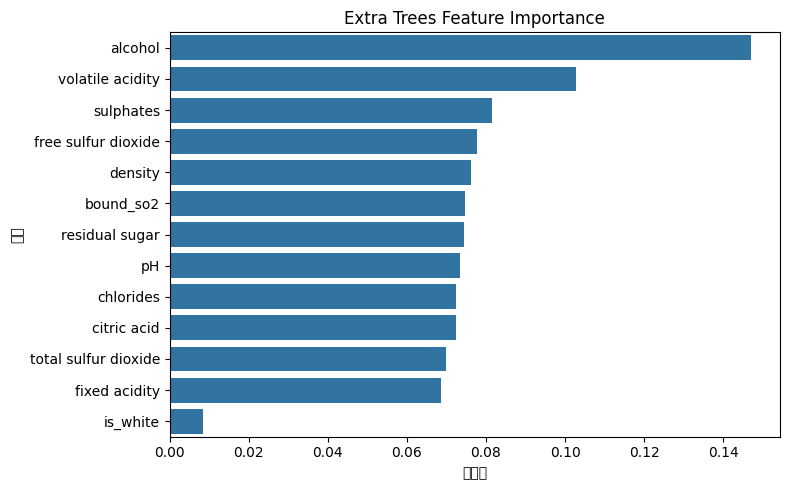

In [8]:
# 탐색 결과에서 최적 파라미터 가져오기
best_params = search.best_params_

best_model = ExtraTreesClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

# 최종 검증
evaluate(best_model, X, y)
evaluate_group(best_model, X, y, groups)

# 전체 Train 데이터로 학습
best_model.fit(X, y)

# 변수 중요도 확인
importance = pd.DataFrame({
    '변수': X.columns,
    '중요도': best_model.feature_importances_
}).sort_values('중요도', ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x='중요도', y='변수')
plt.title('Extra Trees Feature Importance')
plt.tight_layout()
plt.show()

- alcohol이 가장 높은 중요도를 보여 와인 품질 예측에 주요하게 활용되는 변수임을 확인하였다.
- volatile acidity와 sulphates도 상대적으로 높은 중요도를 보였다.
- free sulfur dioxide, density, bound_so2 등 여러 화학 성분 변수가 고르게 활용되었다.
- is_white는 다른 변수에 비해 중요도가 낮게 나타났다.

단, 변수 중요도는 모델의 예측 과정에서 각 변수가 활용된 정도를 나타내며, 변수와 품질 사이의 인과관계나 영향의 방향을 의미하지는 않는다.

###7. Test 예측 및 결과 정리
최종 모델로 Test 데이터를 예측하고 제출 파일을 저장

제출 양식이 제공된 경우 기존 열 구조를 유지

In [9]:
# Test 예측
test_pred = best_model.predict(X_test)

# 제출 파일 생성
submission = pd.read_csv('/content/sample_submission.csv')
submission['quality'] = test_pred

submission.to_csv(
    '/content/submission_extra_trees.csv',
    index=False
)

display(submission.head())

,index,quality
0,0,5
1,1,6
2,2,6
3,3,5
4,4,6


데이콘 제출 결과 Accuracy 0.697